# 03 · Classical Baselines for Short Science Answers

**Research question.** Does directly comparing the student answer with the reference reduce the number of contradictory answers predicted as correct on unseen questions?

**Scope.** This notebook trains on the frozen fit partition (95 questions) and compares models on the development partition (20 other questions). It uses no calibration or official test data for model selection. It retains all original labels and duplicate rows.

Run from the updated repository checkout. In Colab, upload or clone the updated checkout into the runtime; the published copy may not include these new model files yet. Install `requirements-model.txt` in a clean Python 3.12 environment before running.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
candidates = [cwd, *cwd.parents, cwd / "science-answer-benchmark"]
ROOT = next((path for path in candidates if (path / "scripts/run_model_study.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Place the updated science-answer-benchmark checkout in the working directory.")
sys.path.insert(0, str(ROOT / "scripts"))

import run_model_study as study

REPORT_DIR = ROOT / ".model-run" / "development_notebook"
study.REPORTS = REPORT_DIR
fit, dev = study.partition("fit", "development")
for name, frame in [("fit", fit), ("development", dev)]:
    print(f"{name}: {len(frame):,} answers across {frame.question_id.nunique()} questions")
    print(frame["label"].value_counts().to_string())

fit: 3,536 answers across 95 questions
label
correct                         1419
partially_correct_incomplete     964
irrelevant                       753
contradictory                    383
non_domain                        17
development: 715 answers across 20 questions
label
correct                         314
irrelevant                      176
partially_correct_incomplete    148
contradictory                    74
non_domain                        3


## Compare the same inputs in different ways

- **Majority** always predicts the most frequent fit label.
- **Answer only** uses word unigram and bigram TF-IDF features from the student answer.
- **Concatenated** uses the same text representation on the question, reference, and student answer joined into one string.
- **Pair features** keeps answer TF-IDF and adds shared TF-IDF terms, overlap ratios, answer length relative to the reference, and negation indicators.
- **Pair features + LSA** adds two cosine similarities in a 32-dimensional representation learned from the fit texts. LSA is a corpus-trained vector method, not a Transformer.

All learned preprocessing uses the fit partition. Compare fixed-five-class macro F1 and the count of contradictions predicted as correct. Read rare-class estimates alongside the class support.

In [2]:
from contextlib import redirect_stdout
from io import StringIO

with redirect_stdout(StringIO()):
    winner = study.development()

import pandas as pd
metrics = pd.read_csv(REPORT_DIR / "development_metrics.csv")
columns = ["model", "accuracy", "macro_f1_fixed_five", "contradictory_predicted_correct"]
print(metrics[columns].round(3).to_string(index=False))
print(f"Selected: {winner}")

            model  accuracy  macro_f1_fixed_five  contradictory_predicted_correct
         majority     0.439                0.122                               74
      answer_only     0.333                0.330                               40
     concatenated     0.431                0.237                               51
    pair_features     0.455                0.413                               27
pair_features_lsa     0.453                0.407                               33
Selected: pair_features


## Inspect the errors behind the scores

The directly compared inputs improved development macro F1 from 0.237 to 0.413 relative to concatenation. False-correct contradictions fell from 51 to 27 of 74. Adding LSA did not improve the overall development score. These are results for one frozen development split; the three non-domain records make its class-level estimates especially unstable.

Figure saved to: .model-run/development_notebook/development_confusion.png


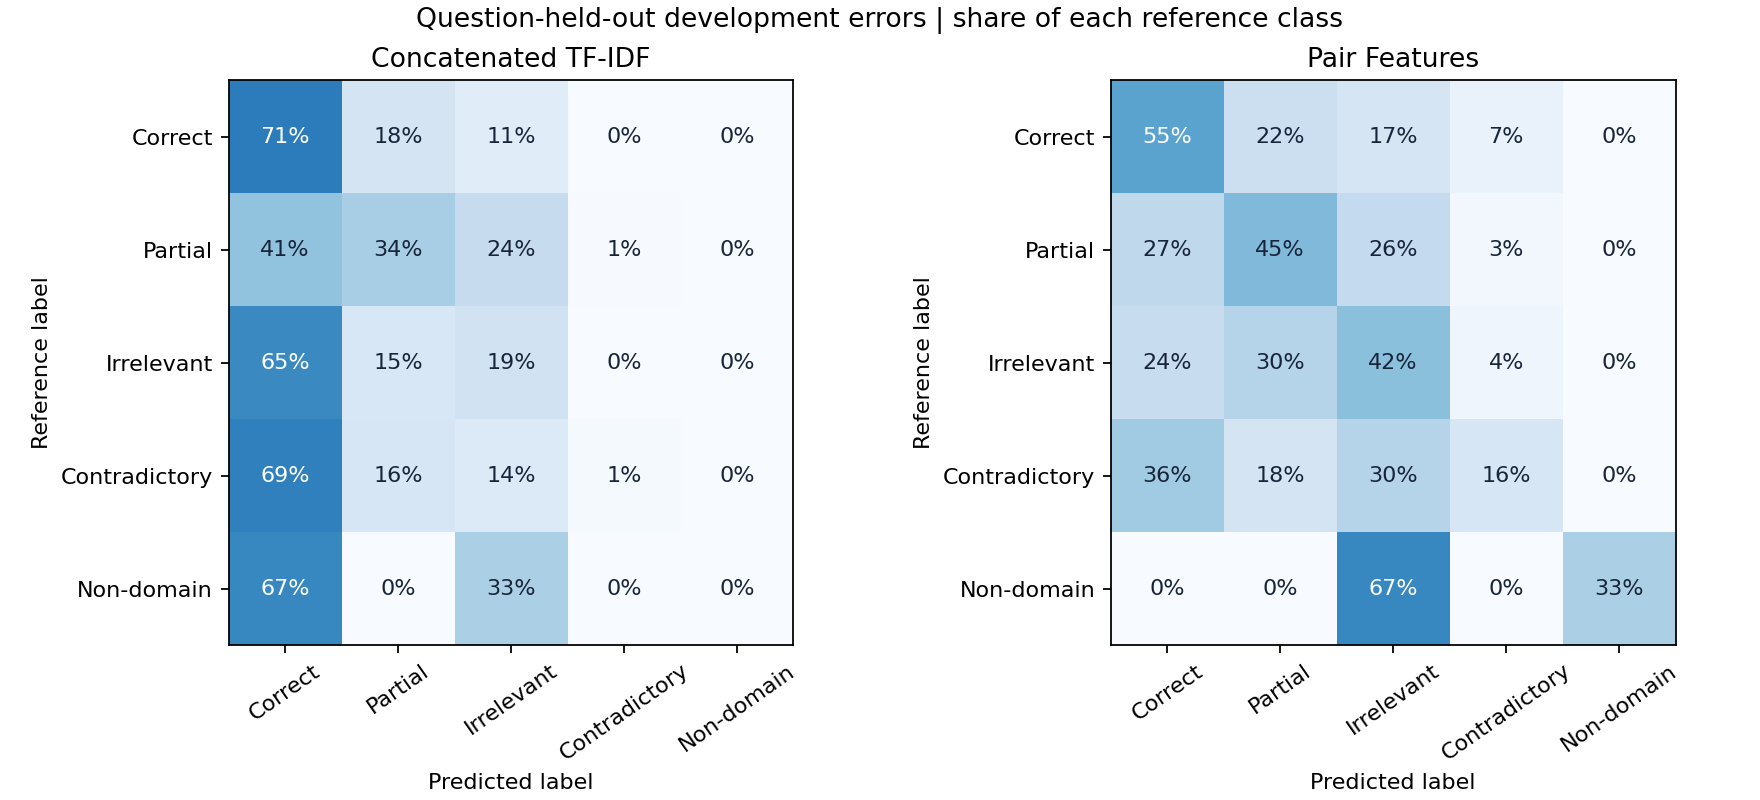

In [3]:
# Show the comparison figure.
try:
    from IPython.display import Image, display
except ImportError:
    print("Figure saved to:", REPORT_DIR / "development_confusion.png")
else:
    display(Image(filename=str(REPORT_DIR / "development_confusion.png")))

In [4]:
from science_models import AnswerClassifier, LABELS

model = AnswerClassifier(winner).fit(study.rows(fit), fit.label)
predictions = [LABELS[i] for i in model.predict_proba(study.rows(dev)).argmax(axis=1)]
examples = study.error_examples(dev, predictions)
for row in examples.itertuples(index=False):
    print(f"\n[{row.question_id}] {row.question_text}")
    print("Reference:", row.reference_answer)
    print("Student:  ", row.student_answer)


[EM_46] Describe how you can tell the difference between the crystals from the calcite test and salt crystals when you observe them in an evaporation dish.
Reference: The crystals have different shapes. Salt crystals are square with little Xs. The calcite crystals are shaped like needles (long and skinny).
Student:   Because the salt crystals were squares with Xs in them and the calcite crystals were and did not make shapes.

[LP_15c] What is the relationship between the amount of effort required to lift the load and its distance from the fulcrum?
Reference: If the effort is applied farther from the fulcrum, less effort will lift the load.
Student:   The closer the effort is to the fulcrum, the harder it is to lift the load.

[ME_17b] Denise made a circuit to light a bulb or run a motor off a D-cell battery. She used a special switch. Below is the schematic diagram of her circuit. The switch is inside the dotted box. Why will the bulb light when she moves the switch to the left?
Refer

## My manual review

For each example, write one or two sentences in English. Identify the specific claim that differs from the reference, and label a possible failure mechanism: reversed relationship, missing condition, explicit negation, shared vocabulary, or annotation ambiguity. Separate what is visible in the text from your hypothesis about why the model failed.

| Question | Claim or condition that differs | Possible failure mechanism |
| --- | --- | --- |
| Add ID | Add your observation | Add your hypothesis |

**Next experiment:** turn repeated failure mechanisms into targeted examples or features. Use development results to make that decision; keep the v1 official results as a fixed reference.